<a href="https://colab.research.google.com/github/mochamadx5/MachineLearning_11_MochamadReza/blob/main/JS08/JS08_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# Install library HDBSCAN jika belum ada
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

In [11]:
# ==========================================
# 0. PERSIAPAN DATASET MALL CUSTOMERS
# ==========================================
# Memuat dataset
df = pd.read_csv('Mall_Customers.csv')

In [13]:
# Mengambil 2 fitur utama untuk clustering 2D
X_raw = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Standarisasi Data (Sangat penting agar parameter cut_distance 0.1-1.0 bekerja)
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

In [14]:
# Fungsi plot kustom
def plot(X_data, labels, probabilities, param, ax):
    unique_labels = set(labels)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1] # Hitam untuk noise

        class_member_mask = (labels == k)
        xy = X_data[class_member_mask]

        # Plot menggunakan data yang sudah di-scale
        ax.scatter(xy[:, 0], xy[:, 1], c=[col], edgecolor='k', s=40,
                   label=f'Cluster {k}' if k != -1 else 'Noise')

    ax.set_title(f"Parameter: {param}")
    # Jika ingin melihat grid/angka sumbu, biarkan xticks/yticks menyala
    # ax.set_xticks(())
    # ax.set_yticks(())

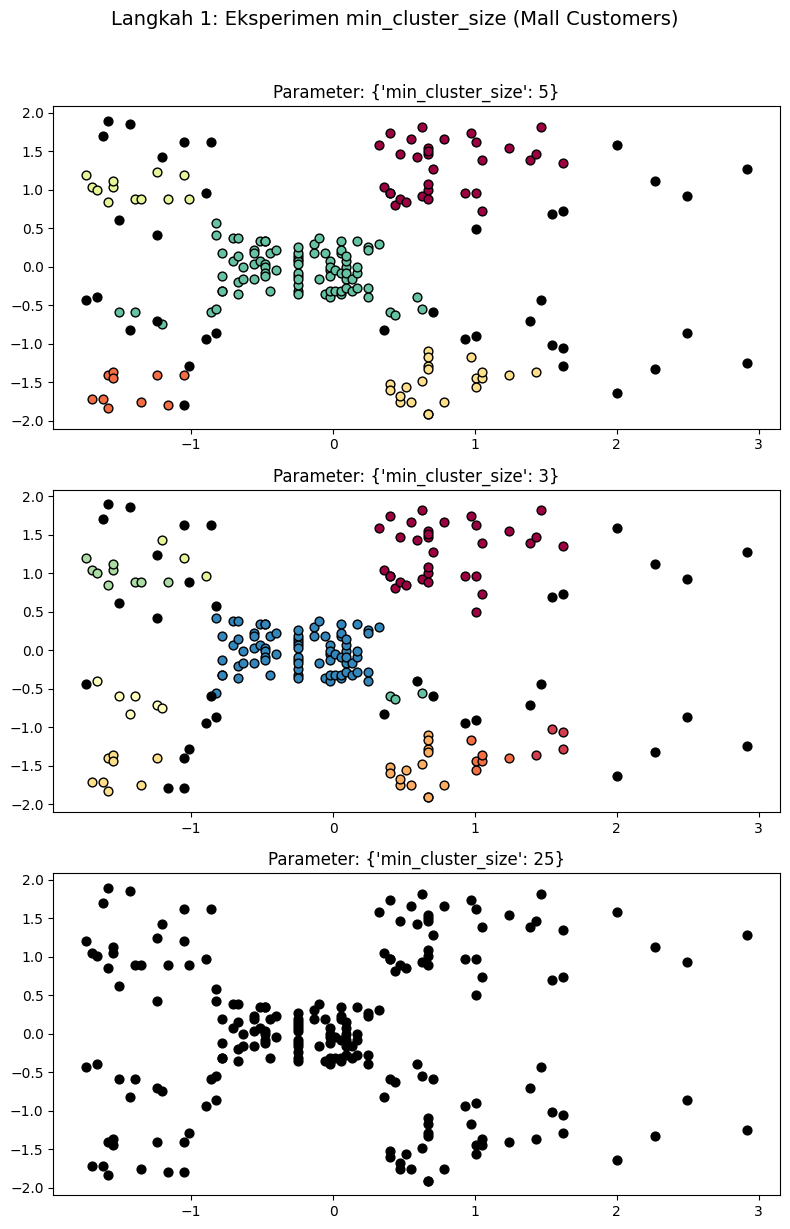

In [15]:
# ==========================================
# LANGKAH 1 - Eksperimen min_cluster_size
# ==========================================
PARAM_1 = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig1, axes1 = plt.subplots(3, 1, figsize=(8, 12))

for i, param in enumerate(PARAM_1):
    hdb1 = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb1.labels_, hdb1.probabilities_, param, ax=axes1[i])
fig1.suptitle("Langkah 1: Eksperimen min_cluster_size (Mall Customers)", fontsize=14, y=1.02)
fig1.tight_layout()
plt.show()

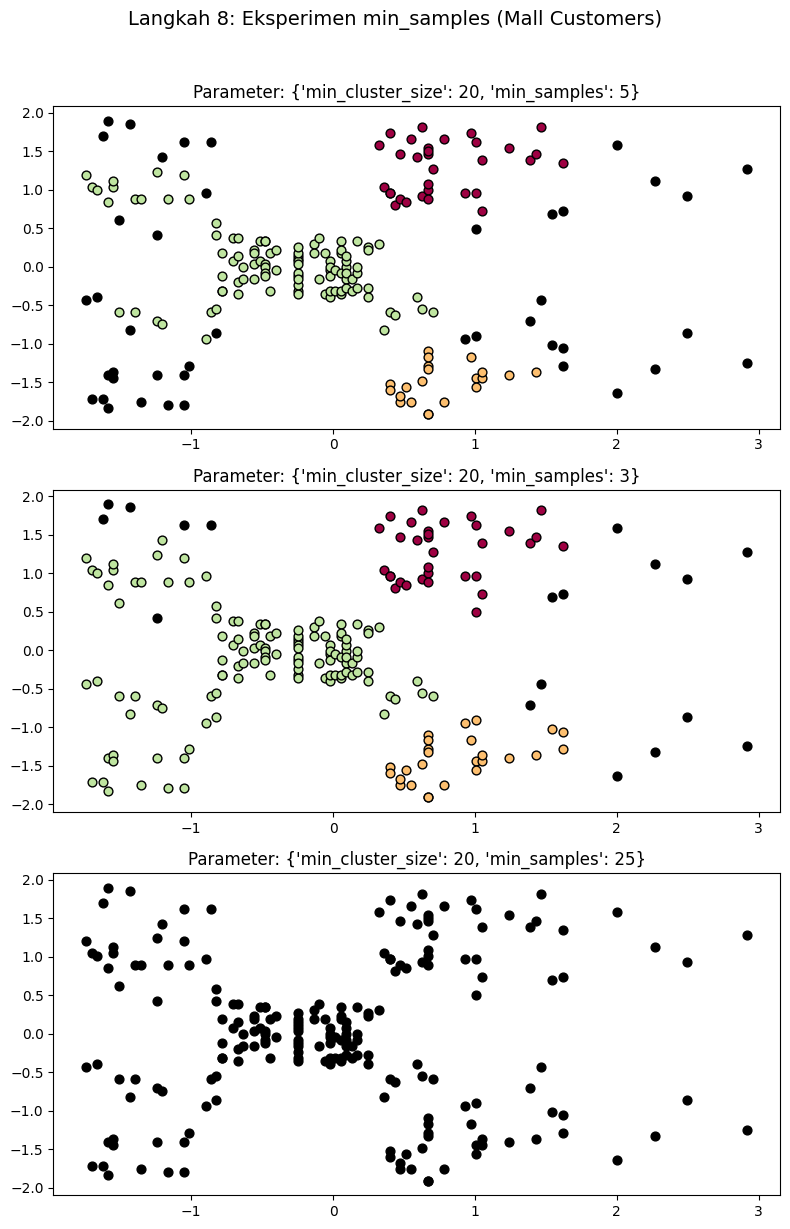

In [16]:
# ==========================================
# LANGKAH 8 - Eksperimen min_samples
# ==========================================
PARAM_8 = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig8, axes8 = plt.subplots(3, 1, figsize=(8, 12))

for i, param in enumerate(PARAM_8):
    hdb8 = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb8.labels_, hdb8.probabilities_, param, ax=axes8[i])
fig8.suptitle("Langkah 8: Eksperimen min_samples (Mall Customers)", fontsize=14, y=1.02)
fig8.tight_layout()
plt.show()

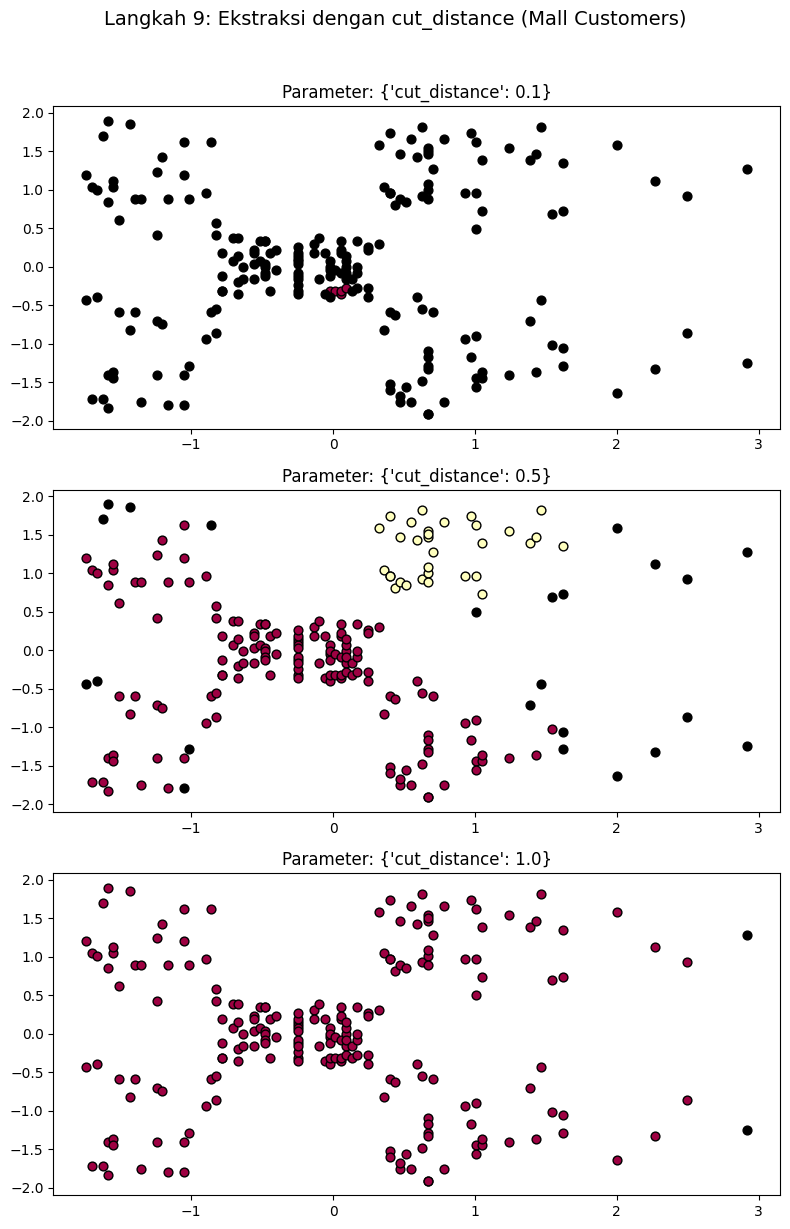

In [17]:
# ==========================================
# LANGKAH 9 - DBSCAN Clustering dari Pohon HDBSCAN
# ==========================================
PARAM_9 = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb_base = hdbscan.HDBSCAN().fit(X)
fig9, axes9 = plt.subplots(len(PARAM_9), 1, figsize=(8, 12))

for i, param in enumerate(PARAM_9):
    labels = hdb_base.dbscan_clustering(**param)
    plot(X, labels, hdb_base.probabilities_, param, ax=axes9[i])
fig9.suptitle("Langkah 9: Ekstraksi dengan cut_distance (Mall Customers)", fontsize=14, y=1.02)
fig9.tight_layout()
plt.show()

In [19]:
# ==========================================
# LANGKAH 10 & 11 - Evaluasi Metrik
# ==========================================
# Mengabaikan Noise (-1) untuk perhitungan metrik agar lebih akurat
mask = hdb_base.labels_ != -1
X_filtered = X[mask]
labels_filtered = hdb_base.labels_[mask]

# Langkah 10: Silhouette Score
sil_score = silhouette_score(X_filtered, labels_filtered)
print(f"\nSilhouette Score (Mall Customers): {sil_score:.4f}")


Silhouette Score (Mall Customers): 0.6018


In [20]:
# Langkah 11: Davies-Bouldin Index
dbi_score = davies_bouldin_score(X_filtered, labels_filtered)
print(f"Davies-Bouldin Index (Mall Customers): {dbi_score:.4f}")

Davies-Bouldin Index (Mall Customers): 0.4604


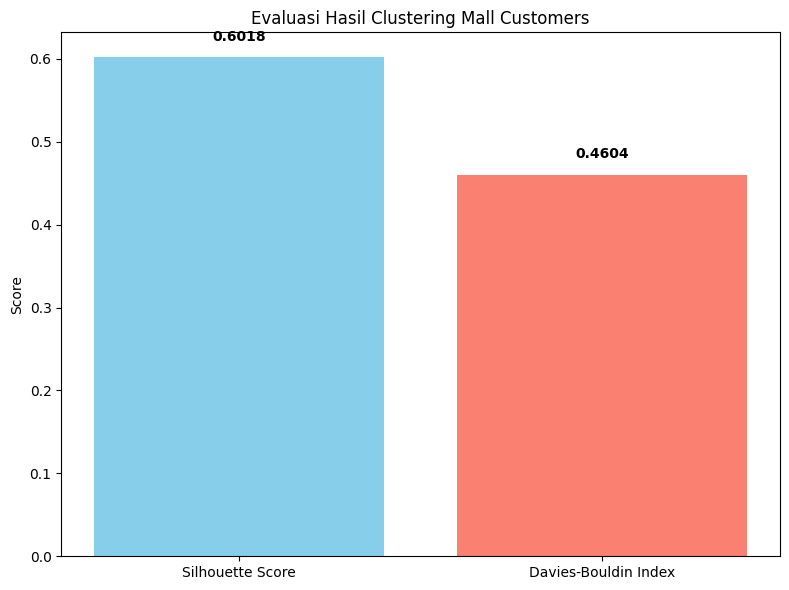

In [21]:
# ==========================================
# LANGKAH 12 - Visualisasi Evaluasi
# ==========================================
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

fig12, ax12 = plt.subplots(figsize=(8, 6))
ax12.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
for i, v in enumerate(scores.values()):
    ax12.text(i, v + 0.02, str(round(v, 4)), ha='center', fontweight='bold')
ax12.set_title("Evaluasi Hasil Clustering Mall Customers")
ax12.set_ylabel("Score")
plt.tight_layout()
plt.show()